# Reimplements Experiment 3 (Exp3_f0s2) of Polonenko, 2026

In [1]:
from pathlib import Path
import subprocess

repo_dir = Path("/content/ABR-Deconv")
if not repo_dir.exists():
    subprocess.run(
        ["git", "clone",
         "https://github.com/jduantc/ABR-Deconv.git",
         str(repo_dir)],
        check=True,
    )
else:
    subprocess.run(
        ["git", "-C", str(repo_dir), "pull", "--ff-only"],
        check=True,
    )

%pip -q install -r /content/ABR-Deconv/prelim_exp3/requirements.txt

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


In [2]:
import sys
import importlib
import numpy as np
import matplotlib.pyplot as plt

# from scipy.fft import next_fast_len
from scipy.signal import butter, sosfiltfilt

sys.path.insert(0, str(repo_dir))

from prelim_exp3 import analysis
importlib.reload(analysis)

# if not hasattr(analysis.mne.filter, "next_fast_len"):
#     analysis.mne.filter.next_fast_len = next_fast_len

<module 'prelim_exp3.analysis' from '/content/ABR-Deconv/prelim_exp3/analysis.py'>

In [3]:
import requests
from tqdm.auto import tqdm

data_dir = Path("/content/abr_data")
base_url = "https://data.nemar.org/on008065/v1.0.0"

subject = "sub-exp301"
run = "01"

stories = ["wizard", "wonderland", "drdolittle"]
story_index = 0
max_trials = 30

bands_khz = [0.5, 1, 2, 4, 8]
ears = ["left", "right"]

def download_file(relative_path):
    destination = data_dir / relative_path

    if destination.exists():
        return destination

    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_name(destination.name + ".part")

    with requests.get(
        f"{base_url}/{relative_path}",
        stream=True,
        timeout=(30, 300),
    ) as response:
        response.raise_for_status()

        with temporary.open("wb") as output:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    output.write(chunk)

    temporary.replace(destination)
    return destination

# Download and load one EEG run

In [4]:
stem = f"{subject}_task-f0s2_run-{run}"
eeg_relative_dir = f"{subject}/eeg"

for extension in ["vhdr", "vmrk", "eeg"]:
    print(f"Downloading/checking {extension}")
    download_file(
        f"{eeg_relative_dir}/{stem}_eeg.{extension}"
    )

events_path = download_file(
    f"{eeg_relative_dir}/{stem}_events.tsv"
)

vhdr_path = data_dir / eeg_relative_dir / f"{stem}_eeg.vhdr"

raw, events = analysis.load_eeg(
    vhdr_path,
    events_path,
    preload=True,
)

print(raw)
print("Channels:", raw.ch_names)
print("Event array:", events.shape)
print(events[:10])

Downloading/checking vhdr
Downloading/checking vmrk
Downloading/checking eeg
Extracting parameters from /content/abr_data/sub-exp301/eeg/sub-exp301_task-f0s2_run-01_eeg.vhdr...
Setting channel info structure...
Reading 0 ... 35773199  =      0.000 ...  3577.320 secs...
Used Annotations descriptions: ['New Segment/', 'Stimulus/S  1', 'Stimulus/S  2', 'Stimulus/S  4', 'Stimulus/S  8']
<RawBrainVision | sub-exp301_task-f0s2_run-01_eeg.eeg, 3 x 35773200 (3577.3 s), ~818.8 MiB, data loaded>
Channels: ['FCzA1', 'FCz', 'A2']
Event array: (8400, 3)
[[151052      0      1]
 [151252      0      4]
 [151452      0      8]
 [151652      0      4]
 [151852      0      4]
 [152052      0      4]
 [152252      0      4]
 [152452      0      4]
 [152652      0      4]
 [152852      0      4]]


# Process EEG / Decode markers / Select trials

In [5]:
eeg, fs_eeg = analysis.process_eeg(raw)

stim_events, clock_adjust = analysis.decode_events(
    events,
    fs_eeg,
)

trials = analysis.select_trials(
    stim_events,
    story_index=story_index,
    max_trials=max_trials,
)

epochs, retained_trials = analysis.extract_epochs(
    eeg,
    trials,
    fs_eeg,
    first_sample=raw.first_samp,
)

print("Clock adjustment:", clock_adjust)
print("Selected trials:", len(trials))
print("Retained trials:", len(retained_trials))
print("EEG epochs:", epochs.shape)
print("First retained rows:")
print(retained_trials[:5])

# The epochs are copies, so the continuous arrays can be deleted
del eeg, raw

Clock adjustment: 0.9999906978210423
Selected trials: 30
Retained trials: 30
EEG epochs: (30, 2, 120000)
First retained rows:
[[ 353302       0       0]
 [ 454636       1       0]
 [ 758426       2       0]
 [1062002       3       0]
 [1366005       4       0]]


# Download stimulus files

In [7]:
# from expyfun.io import read_hdf5

# analysis.read_hdf5 = read_hdf5

In [8]:
def stimulus_relative_path(story_id, token_id):
    story = stories[story_id]
    return (
        f"stimuli/exp3_f0s2/{story}/"
        f"{story}_shifted_{token_id + 1:04d}.hdf5"
    )

def stimulus_path(story_id, token_id):
    return data_dir / stimulus_relative_path(story_id, token_id)

needed = sorted({
    (int(story), int(token))
    for _, token, story in retained_trials
})

for story_id, token_id in tqdm(needed, desc="Stimulus files"):
    download_file(stimulus_relative_path(story_id, token_id))

# Inspect one file before constructing the pulse trains
_, first_token, first_story = retained_trials[0]

stimulus_data = analysis.read_hdf5(
    stimulus_path(int(first_story), int(first_token))
)

print("Stimulus keys:", list(stimulus_data))

Stimulus files:   0%|          | 0/30 [00:00<?, ?it/s]

Stimulus keys: ['fs', 'pulseinds_fake', 'pulseinds_true', 'x_play_band_chirp_CE']


# Core: construct pulse trains and deconvolve

In [9]:
if {"pulseinds_true", "pulseinds_fake"} <= stimulus_data.keys():
    true_key = "pulseinds_true"
    fake_key = "pulseinds_fake"
elif {"pulse_inds", "fake_pulse_inds"} <= stimulus_data.keys():
    true_key = "pulse_inds"
    fake_key = "fake_pulse_inds"
else:
    raise KeyError("Could not identify the stimulus pulse-index keys.")

c, cf = analysis.build_pulse_trains(
    retained_trials,
    stimulus_path,
    fs_eeg,
    clock_adjust,
    true_key=true_key,
    fake_key=fake_key,
)

y = epochs[:, None, None, :, :]

print("Real pulses:", c.shape)
print("Sham pulses:", cf.shape)
print("EEG:", y.shape)

assert c.shape[0] == cf.shape[0] == y.shape[0]
assert c.shape[-1] == cf.shape[-1] == y.shape[-1]

x_isol, x_combined = analysis.deconv(c, cf, y)

assert np.isfinite(x_isol).all(), "Nonfinite band responses."
assert np.isfinite(x_combined).all(), "Nonfinite combined responses."

print("Band responses:", x_isol.shape)
print("Combined responses:", x_combined.shape)

# Keep the responses; release the large input arrays.
del c, cf, y, epochs

Real pulses: (30, 2, 5, 1, 120000)
Sham pulses: (30, 1, 5, 1, 120000)
EEG: (30, 1, 1, 2, 120000)
Band responses: (2, 5, 20000)
Combined responses: (2, 20000)


# Additional filtering after Deconv
(Same setup as original experiment)

In [12]:
from scipy.signal import butter, lfilter

b_post, a_post = butter(
    1, 150,
    btype="highpass",
    fs=fs_eeg,
)

band_curves = lfilter(b_post, a_post, x_isol, axis=-1)
combined_curves = lfilter(b_post, a_post, x_combined, axis=-1)

# Response lag in milliseconds: negative = before the pulse
lags_ms = (
    np.arange(-analysis.n_pre, analysis.n_post)
    / fs_eeg
    * 1000
)

# Display only −5 to 15 ms
plot_window = (lags_ms >= -5) & (lags_ms <= 15)

assert len(lags_ms) == band_curves.shape[-1]

# Plotting

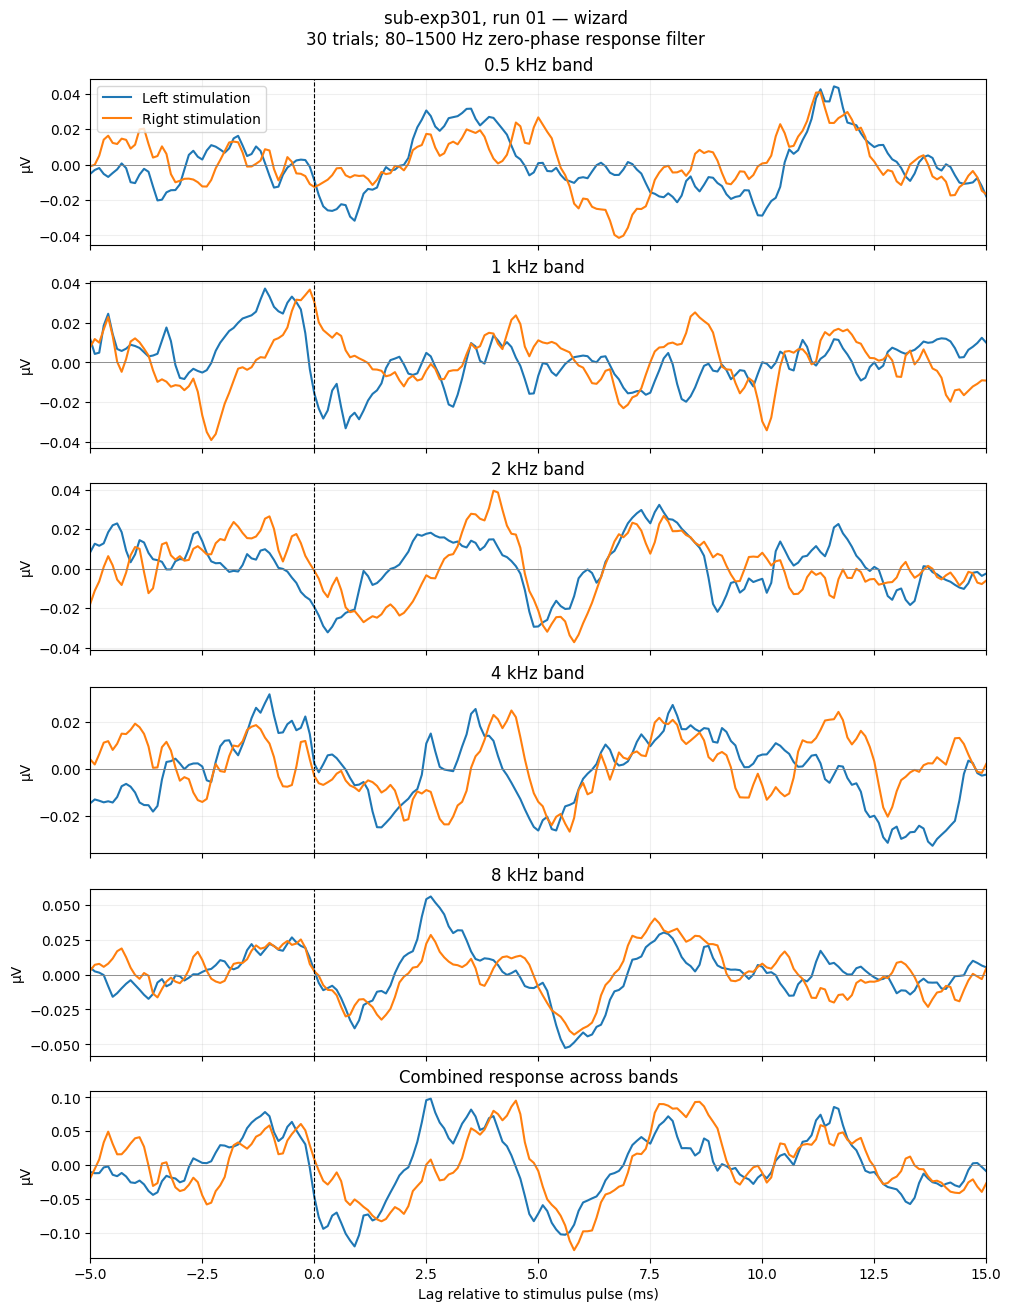

In [13]:
fig, axes = plt.subplots(
    6, 1,
    figsize=(10, 13),
    sharex=True,
    constrained_layout=True,
)

colors = ["tab:blue", "tab:orange"]

for band, frequency in enumerate(bands_khz):
    ax = axes[band]

    for ear, label in enumerate(ears):
        ax.plot(
            lags_ms[plot_window],
            band_curves[ear, band, plot_window],
            color=colors[ear],
            label=f"{label.capitalize()} stimulation",
        )

    ax.set_title(f"{frequency:g} kHz band")
    ax.set_ylabel("µV")

for ear, label in enumerate(ears):
    axes[-1].plot(
        lags_ms[plot_window],
        combined_curves[ear, plot_window],
        color=colors[ear],
        label=f"{label.capitalize()} stimulation",
    )

axes[-1].set_title("Combined response across bands")
axes[-1].set_ylabel("µV")
axes[-1].set_xlabel("Lag relative to stimulus pulse (ms)")

for ax in axes:
    ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
    ax.axhline(0, color="gray", linewidth=0.6)
    ax.set_xlim(-5, 15)
    ax.grid(alpha=0.2)

axes[0].legend()

fig.suptitle(
    f"{subject}, run {run} — {stories[story_index]}\n"
    f"{len(retained_trials)} trials; "
    "80–1500 Hz zero-phase response filter"
)

plt.show()